# 2. Regression — Predicting `target_regression`
**APRAU 2026/27 — Group 18**

Sections:
1. Setup & Data Loading
2. Preprocessing
3. Simple Linear Regression
4. Multiple Linear Regression
5. Comparison & Discussion

## 1. Setup

In [1]:
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18_cleaned.csv'
else:
    DATASET_PATH = '../dataset_grupo_18_cleaned.csv'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler, LabelEncoder

plt.rcParams['figure.figsize'] = (10, 5)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Data Loading & Preprocessing

In [3]:
df = pd.read_csv(DATASET_PATH)
print(f'Shape: {df.shape}')
df.head()

Shape: (2000, 32)


,age_level,gender,bmi_level,smoking,age,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,...,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,plasma_value,ldl_alternative,target_regression,target_class
0,Middle,Female,Overweight,Never,41,26.039307,5.406343,287.000000,8.393934,176.000000,...,8.477600,74.022857,64.889143,130.259429,Secondary,Employed,1.111734,128.726611,97.0,N
1,Mature,Female,Normal,Current,47,20.800000,6.945000,245.000000,9.800000,60.000000,...,11.400000,88.000000,67.000000,118.000000,Secondary,Employed,1.162052,129.057613,96.0,DI
2,Senior,Male,Normal,Former,76,20.500000,5.362764,218.000000,6.300000,86.000000,...,8.700000,84.000000,59.000000,105.000000,Secondary,Unemployed,1.424600,129.050057,169.0,N
3,Young,Female,Overweight,Never,20,29.810000,4.800000,225.928571,7.000592,227.250000,...,8.439149,73.553191,65.804255,133.378723,Primary,Unemployed,1.063741,164.000000,90.0,N
4,Middle,Male,Overweight,Former,35,27.320000,6.000000,225.071183,7.040413,148.762342,...,8.429047,74.042480,63.850746,130.987371,Secondary,Unemployed,0.952215,130.545353,158.0,N


In [4]:
# Encode categorical columns
df_enc = df.copy()
for col in df_enc.select_dtypes(include='object').columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

TARGET = 'target_regression'
FEATURES = [c for c in df_enc.columns if c not in [TARGET, 'target_class']]

X = df_enc[FEATURES]
y = df_enc[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (1600, 30) | Test: (400, 30)


In [5]:
def evaluate(name, y_true, y_pred):
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'[{name}]  R²={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}')
    return {'Model': name, 'R²': r2, 'MAE': mae, 'RMSE': rmse}

## 3. Simple Linear Regression

In [6]:
# Test each feature individually and rank by R²
results_simple = []
for feat in FEATURES:
    model = LinearRegression()
    model.fit(X_train[[feat]], y_train)
    y_pred = model.predict(X_test[[feat]])
    r2 = r2_score(y_test, y_pred)
    results_simple.append({'Feature': feat, 'R²': r2})

results_simple = pd.DataFrame(results_simple).sort_values('R²', ascending=False)
results_simple.head(10)

,Feature,R²
6,HbA1c_level,0.008299
11,family_history,0.001074
12,stress_level,0.001042
4,age,0.000096
2,bmi_level,-0.000148
0,age_level,-0.000307
10,physical_activity,-0.000727
1,gender,-0.000870
15,blood_pressure,-0.001010
27,employment_status,-0.001112


Best single feature: HbA1c_level
[Simple LR]  R²=0.0083  MAE=30.8520  RMSE=38.3962


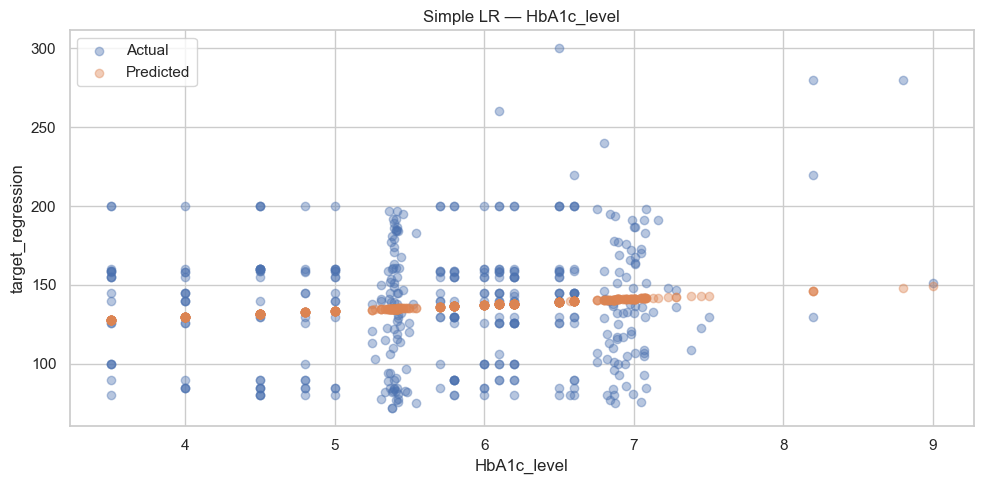

In [7]:
# Best single feature model
best_feat = results_simple.iloc[0]['Feature']
print(f'Best single feature: {best_feat}')

model_slr = LinearRegression()
model_slr.fit(X_train[[best_feat]], y_train)
y_pred_slr = model_slr.predict(X_test[[best_feat]])

metrics = [evaluate('Simple LR', y_test, y_pred_slr)]

plt.scatter(X_test[best_feat], y_test, alpha=0.4, label='Actual')
plt.scatter(X_test[best_feat], y_pred_slr, alpha=0.4, label='Predicted')
plt.xlabel(best_feat)
plt.ylabel('target_regression')
plt.legend()
plt.title(f'Simple LR — {best_feat}')
plt.tight_layout()
plt.show()

## 4. Multiple Linear Regression

In [8]:
# All features
model_mlr_all = LinearRegression()
model_mlr_all.fit(X_train, y_train)
y_pred_mlr_all = model_mlr_all.predict(X_test)
metrics.append(evaluate('Multiple LR (all features)', y_test, y_pred_mlr_all))

[Multiple LR (all features)]  R²=-0.0319  MAE=31.6520  RMSE=39.1666


In [9]:
# Top N features (from Simple LR ranking)
TOP_N = 5
top_feats = results_simple.head(TOP_N)['Feature'].tolist()
print(f'Top {TOP_N} features: {top_feats}')

model_mlr_top = LinearRegression()
model_mlr_top.fit(X_train[top_feats], y_train)
y_pred_mlr_top = model_mlr_top.predict(X_test[top_feats])
metrics.append(evaluate(f'Multiple LR (top {TOP_N})', y_test, y_pred_mlr_top))

Top 5 features: ['HbA1c_level', 'family_history', 'stress_level', 'age', 'bmi_level']
[Multiple LR (top 5)]  R²=0.0154  MAE=30.7743  RMSE=38.2582


## 5. Comparison & Discussion

In [10]:
metrics_df = pd.DataFrame(metrics).set_index('Model')
metrics_df

,R²,MAE,RMSE
Model,,,
Simple LR,0.008299,30.851973,38.396230
Multiple LR (all features),-0.031896,31.652037,39.166624
Multiple LR (top 5),0.015416,30.774293,38.258204


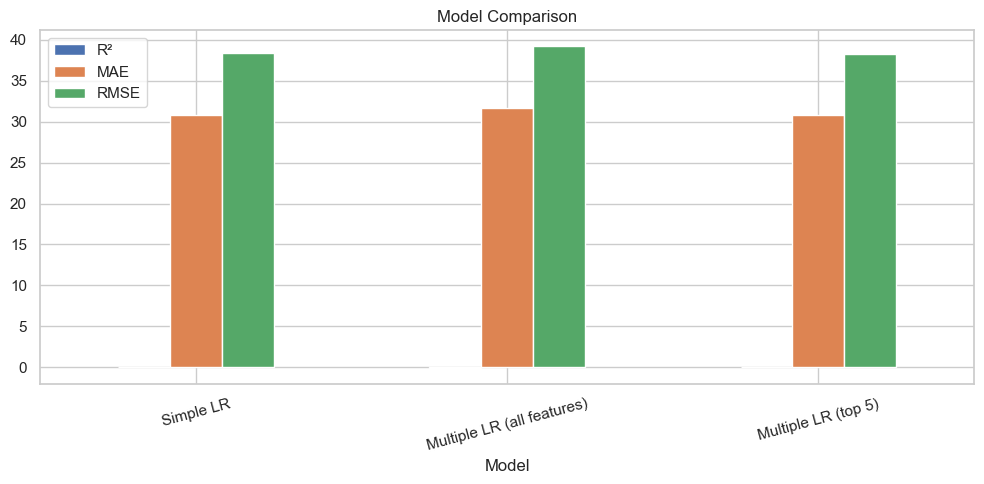

In [11]:
metrics_df[['R²', 'MAE', 'RMSE']].plot(kind='bar', figsize=(10, 5))
plt.title('Model Comparison')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Discussion

*(Fill in after running the models)*

- **Best single feature and justification:**
- **Best feature combination and justification:**
- **Simple vs Multiple LR comparison:**